# Working with raster data in Python

This Jupyter notebook does the following:

- Download and display a swisstopo SWISSIMAGE aerial image in GeoTIFF format.
- Plot histograms of the red, green, and blue image bands.
- Create a square polygon in Swiss LV95 coordinates, save it as a shapefile, and display it over the image.
- Clip the raster to the polygon and display the cropped image.
- Save the clipped raster as a GeoTIFF and inspect its metadata.

## Libraries and Settings

In [1]:
# Libraries
import os
import pprint
from pathlib import Path
import requests
import numpy as np
import pandas as pd

import fiona
import geopandas as gpd

import rasterio
from rasterio import plot
import rasterio.mask

from shapely.geometry import Polygon

import matplotlib.patches as patches
from matplotlib import pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Keep downloaded files and outputs in this lesson folder.
lesson_dir = Path.cwd()
if not (lesson_dir / 'raster_analysis.ipynb').is_file():
    if (lesson_dir / 'Week_11' / '06_Python_Raster_Data').is_dir():
        lesson_dir = lesson_dir / 'Week_11' / '06_Python_Raster_Data'
    elif (lesson_dir / '06_Python_Raster_Data').is_dir():
        lesson_dir = lesson_dir / '06_Python_Raster_Data'
    else:
        raise FileNotFoundError('Could not locate the 06_Python_Raster_Data lesson folder.')
os.chdir(lesson_dir)

print(os.getcwd())

/workspaces/ARM-Stejsnat/Week_11/06_Python_Raster_Data


## Download Zurich SWISSIMAGE raster (.geotiff) from SwissTopo

Source: https://www.swisstopo.admin.ch/de/orthobilder-swissimage-10-cm

In [2]:
# Download a Zurich SWISSIMAGE tile in LV95 coordinates.
url = "https://data.geo.admin.ch/ch.swisstopo.swissimage-dop10/swissimage-dop10_2022_2683-1247/swissimage-dop10_2022_2683-1247_0.1_2056.tif"
image_path = Path('swissimage_zurich.tif')
if not image_path.is_file():
    download_path = Path('swissimage_zurich.tif.download')
    with requests.get(url, stream=True, timeout=(15, 300)) as response:
        response.raise_for_status()
        with download_path.open('wb') as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    download_path.replace(image_path)
print(f'Using {image_path} ({image_path.stat().st_size:,} bytes)')

Using swissimage_zurich.tif (62,446,108 bytes)


Raster CRS: EPSG:2056; bands: 3; bounds: BoundingBox(left=2683000.0, bottom=1247000.0, right=2684000.0, top=1248000.0)


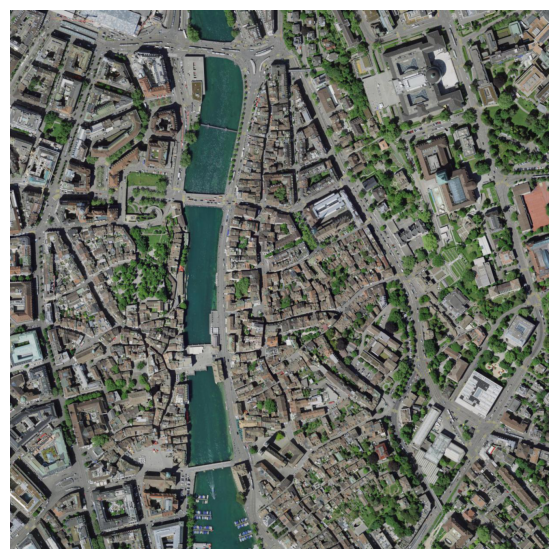

In [3]:
# Import raster
with rasterio.open('swissimage_zurich.tif') as src:
    print(f'Raster CRS: {src.crs}; bands: {src.count}; bounds: {src.bounds}')
    preview = src.read(
        (1, 2, 3),
        out_shape=(3, min(1000, src.height), min(1000, src.width)),
        resampling=rasterio.enums.Resampling.average,
    )

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(np.transpose(preview, (1, 2, 0)))
ax.axis('off')
plt.show()

## Show histogram of RGB colors

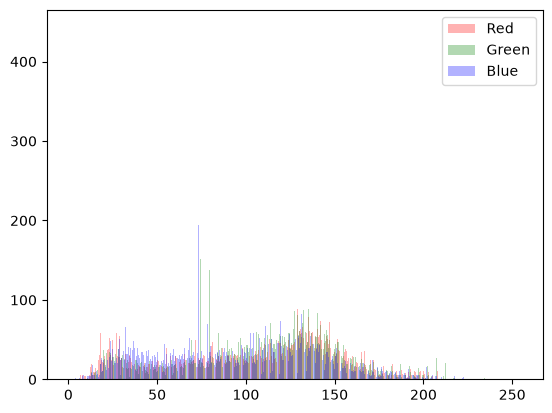

In [4]:
# Open raster
with rasterio.open('swissimage_zurich.tif') as src:
    rgb_sample = src.read(
        (1, 2, 3),
        out_shape=(3, min(1000, src.height), min(1000, src.width)),
        resampling=rasterio.enums.Resampling.average,
    )

# Plot a representative sample instead of flattening all 100 million pixels
red, green, blue = rgb_sample

# Plot a histogram
plt.hist(red, bins=50, color='red', alpha=0.3, label='Red')
plt.hist(green, bins=50, color='green', alpha=0.3, label='Green')
plt.hist(blue, bins=50, color='blue', alpha=0.3, label='Blue')

plt.legend(loc='upper right')
plt.show()


## Masking a raster using a shapefile

### Create a shapefile

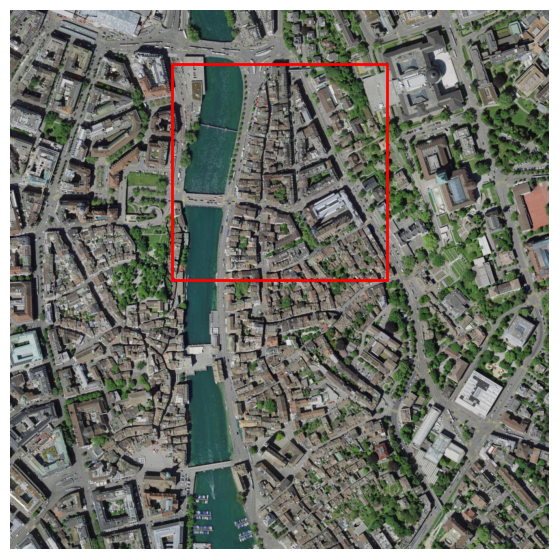

In [5]:
# Read raster
# Bottom left corner of square (LV95 coordinates)
x1, y1 = 2683300, 1247500

# Side length of square in meters
size = 400

# Create the other three corners
coordinates = [(x1, y1), (x1, y1 + size), (x1 + size, y1 + size), (x1 + size, y1)]

# Create a shapely polygon from the coordinates
polygon = Polygon(coordinates)

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame(index=[0], geometry=[polygon], crs='EPSG:2056')

# Save the GeoDataFrame as a shapefile
gdf.to_file('municipality_part_zuerich.shp')

# Plot a reduced raster preview with the selected area
with rasterio.open('swissimage_zurich.tif') as src:
    preview = src.read(
        (1, 2, 3),
        out_shape=(3, min(1000, src.height), min(1000, src.width)),
        resampling=rasterio.enums.Resampling.average,
    )
    bounds = src.bounds

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(np.transpose(preview, (1, 2, 0)), extent=(bounds.left, bounds.right, bounds.bottom, bounds.top))
patch = patches.Polygon(coordinates, fill=False, edgecolor='red', linewidth=2)
ax.add_patch(patch)
ax.axis('off')
plt.show()

### Masking the raster

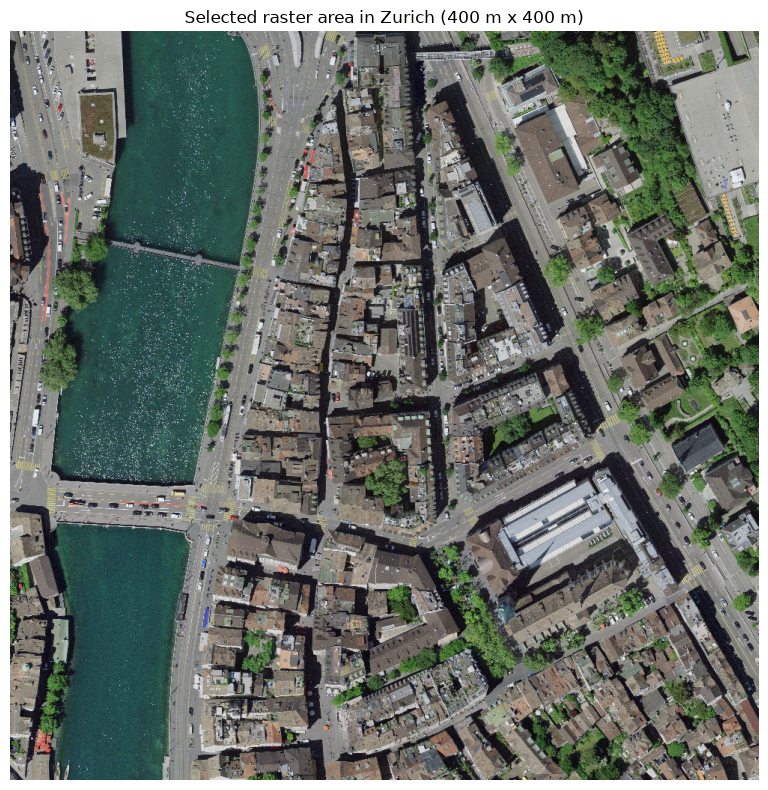

In [6]:
# Read shapefile
with fiona.open('municipality_part_zuerich.shp', 'r') as shapefile:
    shapes = [feature["geometry"] for feature in shapefile]

# Mask the raster with the shapefile
with rasterio.open('swissimage_zurich.tif') as src:
    out_image, out_transform = rasterio.mask.mask(src, shapes, crop=True)
    out_meta = src.meta.copy()

# Plot the masked raster
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.transpose(out_image[:, ::4, ::4], (1, 2, 0)))

# Hide the axes
ax.axis('off')

ax.set_title(f'Selected raster area in Zurich ({size} m x {size} m)')
fig.tight_layout()
fig.savefig(Path('..') / 'selected_raster_area.png', dpi=200, bbox_inches='tight')
plt.show()

## Save masked raster as .geotiff

In [7]:
# Update metadata
out_meta.update({
    "driver": "GTiff",
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "transform": out_transform
})

# Write the masked image to a new GeoTIFF file
with rasterio.open('masked_swissimage_zurich.tif', 'w', **out_meta) as dest:
    dest.write(out_image)

# Print metadata
print('Meta data:')
pprint.pprint(out_meta)

Meta data:
{'count': 3,
 'crs': CRS.from_wkt('PROJCS["CH1903+ / LV95",GEOGCS["CH1903+",DATUM["CH1903+",SPHEROID["Bessel 1841",6377397.155,299.1528128,AUTHORITY["EPSG","7004"]],AUTHORITY["EPSG","6150"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4150"]],PROJECTION["Hotine_Oblique_Mercator_Azimuth_Center"],PARAMETER["latitude_of_center",46.9524055555556],PARAMETER["longitude_of_center",7.43958333333333],PARAMETER["azimuth",90],PARAMETER["rectified_grid_angle",90],PARAMETER["scale_factor",1],PARAMETER["false_easting",2600000],PARAMETER["false_northing",1200000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2056"]]'),
 'driver': 'GTiff',
 'dtype': 'uint8',
 'height': 4000,
 'nodata': None,
 'transform': Affine(0.1, 0.0, 2683300.0,
       0.0, -0.1, 1247900.0),
 'width': 4000}


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [8]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-27 09:05:15
Python Version: 3.11.18
-----------------------------------
